# Algorithm 1 on an E–I network of Hodgkin–Huxley neurons

This notebook includes the code for the second example of the paper "A Novel Algorithm to Simulate Conductance-based Neuronal Networks": the excitatory–inhibitory (E–I) network of Fig. 3, which generates a PING-like rhythm.

**The network.** It has $n_E$ excitatory (E) and $n_I$ inhibitory (I) Hodgkin–Huxley neurons.
* Every E neuron excites every I neuron through a **fast** synapse, and every I neuron inhibits every E neuron through a **slow** synapse. There are no E→E or I→I connections.
* Only the E neurons receive an external input. The I neurons are driven by the E population alone.
* The neurons are heterogeneous: their maximal conductances and input amplitudes are drawn around nominal values with a fixed random seed, and the inputs carry frozen noise.
* Each synapse onto a neuron has strength $\bar g / n_{\text{pre}}$, so the total synaptic drive a neuron receives does not depend on the network size.

Each neuron sends its synapses through one gating variable $s_j$, driven by its own voltage:
$$\dot s_j = \alpha_s(v_j)\,(1 - s_j) - s_j/\tau .$$
All synapses onto neuron $n$ share the same strength and reversal potential, so they add up to a single branch, and neuron $n$ obeys (equation (2) of the paper, with $C = 1$)
$$\dot v_n = -\sum_{i \in \{\text{Na},\,\text{K},\,\text{L}\}} g_{i,n}\,\bigl(v_n - E_i\bigr) - g_{\text{syn},n}\,\bigl(v_n - E_{\text{syn},n}\bigr) + u_n, \qquad g_{\text{syn},n} = \frac{\bar g}{n_{\text{pre}}} \sum_{j \,\in\, \text{pre}(n)} s_j .$$

**Algorithm 1.** Starting from a guess $v^0$ of all voltage signals on $[0, T]$, each iteration does two things:

**Step 1: Freeze the memristors.** Evaluate every conductance along the current iterate $v^k$. The gates $m, h, n$ of neuron $n$ follow $v_n^k$, and the synaptic gate $s_j$ follows the presynaptic voltage $v_j^k$. Each of them is a scalar LTV equation once the voltages are given.

**Step 2: Solve the RC circuits.** With the conductances frozen, the neurons decouple into one scalar LTV equation per neuron,
$$\dot v_n^{k+1} = -\eta_n(t)\, v_n^{k+1} + \xi_n(t), \qquad v_n^{k+1}(0) = v_0,$$
with $\eta_n = \sum_i g_{i,n}^k + g_{\text{syn},n}^k$ and $\xi_n = \sum_i g_{i,n}^k E_i + g_{\text{syn},n}^k E_{\text{syn},n} + u_n$. These equations are solved in parallel and in closed form.

The iteration stops once $\max_n \max_t |v_n^{k+1}(t) - v_n^k(t)| \le \varepsilon$.

**Performance.** Algorithm 1 runs on the GPU (in Colab: *Runtime → Change runtime type → T4 GPU*), with one GPU thread per neuron. Each thread marches through time, updates the gates $m, h, n$ along the old iterate, and solves the voltage equation for the new iterate in the same pass (Steps 1 and 2 fused). The synaptic gates are computed first, followed by a parallel sum over each population, because every neuron needs the summed activity of the other population. The computation runs in double precision, and the numerics are identical to the CPU version up to round-off. The GPU pays off for large networks (thousands of neurons). For a few dozen neurons, most threads are idle and the CPU version is faster.

In [61]:
# Requires a GPU runtime (Colab: Runtime -> Change runtime type -> T4 GPU).
# If the check below fails with a CUDA/NVVM error, run:  !pip install -q "numba-cuda[cu12]"  and restart the session.
import math
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from numba import cuda, float64

# Numba warns when a kernel is launched on few blocks. This is expected here (one thread per neuron).
warnings.filterwarnings("ignore", message="Grid size")

if not cuda.is_available():
    raise RuntimeError("No CUDA GPU found. In Colab: Runtime -> Change runtime type -> T4 GPU.")
cuda.detect()   # prints the GPU that will be used

Found 1 CUDA devices
id 0                Tesla T4                              [SUPPORTED]
                      Compute Capability: 7.5
                           PCI Device ID: 4
                              PCI Bus ID: 0
                                    UUID: GPU-67f354fe-f717-2b43-ee33-5f2d7fde2415
                                Watchdog: Disabled
             FP32/FP64 Performance Ratio: 32
                            FP16 Support: Yes
                            BF16 Support: No
                             FP8 Support: No
Summary:
	1/1 devices are supported


True

## Parameters

In [62]:
# Network
N_E, N_I = 40, 10   # number of excitatory and inhibitory neurons (paper: 40 + 10, 400 + 100 and 4000 + 1000)
SEED = 0                # random seed for the heterogeneity and the noise

# Simulation window
T_FINAL = 100.0         # ms - Simulation window
DT = 0.1                # ms - Time vector discretization step
WINDOW = 100.0          # ms - Algorithm 1 is applied to consecutive windows of this length
                        #      (WINDOW = T_FINAL: a single window, as in the paper)

# Hodgkin–Huxley neurons (nominal values)
G_NA, G_K, G_L = 120.0, 36.0, 0.3       # maximal conductances (mS/cm²)
E_NA, E_K, E_L = 50.0, -77.0, -54.387   # reversal potentials (mV)
V0 = -65.0                              # initial voltage (mV); the gates start at their steady state
HETERO = 0.1                            # relative standard deviation of the maximal conductances

# External input to the E neurons: on from T_ON to T_OFF, with frozen noise
I_E, I_E_SPREAD = 10.0, 0.1             # mean amplitude (µA/cm²) and its relative standard deviation across neurons
T_ON, T_OFF = 5.0, 80.0                 # ms
NOISE = 1.0                             # standard deviation of the noise (µA/cm²)

# Synapses: g_syn onto a neuron = (G / n_pre) * sum of the presynaptic gating variables s_j
G_EI, E_EXC, TAU_EI = 0.5, 0.0, 2.0       # E -> I (fast): total maximal conductance (mS/cm²), reversal (mV), decay (ms)
G_IE, E_INH, TAU_IE = 4.0, -80.0, 7.0     # I -> E (slow)
ALPHA_SYN, V_SYN, K_SYN = 5.0, 0.0, 2.0   # alpha_s: maximal rate (1/ms), midpoint (mV), slope (mV)

# Solver
TOL = 1e-6         # stopping tolerance ε (mV), per window
MAX_ITERS = 1300   # maximum number of iterations allowed, per window

## The network

Neurons $0, \dots, n_E - 1$ are excitatory and the remaining $n_I$ are inhibitory. Signals are stored with shape (time, neuron). The input of an E neuron is a smooth pulse with a random amplitude, plus noise that is drawn once and then kept fixed ("frozen").

In [63]:
t = np.arange(0, T_FINAL + DT / 2, DT)    # Time vector
N = N_E + N_I
is_exc = np.arange(N) < N_E               # True for the E neurons
exc, inh = slice(0, N_E), slice(N_E, N)

# Heterogeneous maximal conductances, one value per neuron
rng = np.random.default_rng(SEED)
g_na = G_NA * (1 + HETERO * rng.standard_normal(N))
g_k = G_K * (1 + HETERO * rng.standard_normal(N))
g_l = G_L * (1 + HETERO * rng.standard_normal(N))

# External input u, shape (time, neuron). The I neurons get no input.
amplitude = I_E * (1 + I_E_SPREAD * rng.standard_normal(N_E))            # one amplitude per E neuron
noise = NOISE * rng.standard_normal((len(t), N_E))                       # fixed by the seed
pulse = 0.5 * (np.tanh((t - T_ON) / 1.0) - np.tanh((t - T_OFF) / 1.0))   # smooth on at T_ON, off at T_OFF
u = np.zeros((len(t), N))
u[:, exc] = pulse[:, None] * (amplitude + noise)

# Synapses
E_syn = np.where(is_exc, E_INH, E_EXC)       # reversal of the synapses a neuron receives: E is inhibited, I is excited
tau_syn = np.where(is_exc, TAU_EI, TAU_IE)   # decay of the synapses a neuron sends


def rates(v):
    """Opening and closing rates (alpha, beta) of the gates m, h, n at voltage v."""
    alpha_m = 0.1 * (v + 40.0 + 1e-5) / (1.0 - np.exp(-(v + 40.0 + 1e-5) / 10.0))
    beta_m = 4.0 * np.exp(-(v + 65.0) / 18.0)
    alpha_h = 0.07 * np.exp(-(v + 65.0) / 20.0)
    beta_h = 1.0 / (1.0 + np.exp(-(v + 35.0) / 10.0))
    alpha_n = 0.01 * (v + 55.0 + 1e-5) / (1.0 - np.exp(-(v + 55.0 + 1e-5) / 10.0))
    beta_n = 0.125 * np.exp(-(v + 65.0) / 80.0)
    return alpha_m, beta_m, alpha_h, beta_h, alpha_n, beta_n


# Initial state, one row per variable (v, m, h, n, s) and one column per neuron:
# every neuron starts at V0 with its gates at their steady state and its synapses closed
am, bm, ah, bh, an, bn = rates(V0)
x0 = np.outer([V0, am / (am + bm), ah / (ah + bh), an / (an + bn), 0.0], np.ones(N))

## Linear time-varying solver

Both steps reduce to scalar LTV equations of the form $\dot x = -a(t)\,x + b(t)$. On each time step, $a$ and $b$ are replaced by their averages and the equation is solved exactly. This is the closed-form solver `solve_ltv` of the single-neuron notebook (2nd order).

On the GPU, each thread advances its own equation one time step at a time, so the solver is written as a single step. `ltv_step` is a *device function*: it can only be called from the GPU kernels below.

In [64]:
@cuda.jit(device=True)
def ltv_step(x, a0, b0, a1, b1, dt):
    """One time step of x' = -a x + b. (a0, b0) and (a1, b1) are the values of a and b at its two ends."""
    a = 0.5 * (a0 + a1)
    decay = math.exp(-a * dt)
    return decay * x + (1.0 - decay) * 0.5 * (b0 + b1) / a

## Step 1: synaptic conductances

Two kernels map the voltage iterate $v^k$ to the synaptic conductance signals. Arrays on the GPU have shape (time, neuron), so that neighbouring threads, which handle neighbouring neurons, read neighbouring memory addresses.

* `synaptic_gates`: one thread per neuron solves $\dot s_j = \alpha_s(v_j^k)(1 - s_j) - s_j/\tau$ along $v_j^k$, with $\alpha_s(v) = \bar\alpha \,/\, \bigl(1 + e^{-(v - v_s)/k_s}\bigr)$.
* `population_sums`: sums the gates $s_j$ over the E and over the I population at every time. One block of threads per time step shares the work: each thread adds up a part of the neurons, and the partial sums are then combined pairwise in shared memory.

The synaptic conductance onto an I neuron is then $(\bar g_{EI} / n_E) \sum_{j \in E} s_j$, and onto an E neuron $(\bar g_{IE} / n_I) \sum_{j \in I} s_j$.

In [65]:
THREADS = 128       # threads per block for the kernels with one thread per neuron
SUM_THREADS = 256   # threads per block for the population sums (must be a power of two)


@cuda.jit
def synaptic_gates(v, s0, tau, alpha_max, v_half, slope, dt, s):
    """Step 1, synapses: one thread per neuron solves s' = alpha_s(v)(1 - s) - s / tau along v."""
    j = cuda.grid(1)                # the neuron of this thread
    n_t, n_neurons = v.shape
    if j >= n_neurons:
        return
    beta = 1.0 / tau[j]
    alpha_prev = alpha_max / (1.0 + math.exp(-(v[0, j] - v_half) / slope))
    x = s0[j]
    s[0, j] = x
    for i in range(n_t - 1):
        alpha_next = alpha_max / (1.0 + math.exp(-(v[i + 1, j] - v_half) / slope))
        x = ltv_step(x, alpha_prev + beta, alpha_prev, alpha_next + beta, alpha_next, dt)
        s[i + 1, j] = x
        alpha_prev = alpha_next


@cuda.jit
def population_sums(s, n_e, sum_e, sum_i):
    """Step 1, synapses: one block per time step sums the gates s over the E and over the I population."""
    i = cuda.blockIdx.x             # the time step of this block
    tid = cuda.threadIdx.x          # the thread within the block
    n_neurons = s.shape[1]
    part_e = cuda.shared.array(SUM_THREADS, dtype=float64)
    part_i = cuda.shared.array(SUM_THREADS, dtype=float64)

    # Each thread adds up the neurons tid, tid + SUM_THREADS, tid + 2 * SUM_THREADS, ...
    acc_e = 0.0
    acc_i = 0.0
    for j in range(tid, n_neurons, SUM_THREADS):
        if j < n_e:
            acc_e += s[i, j]
        else:
            acc_i += s[i, j]
    part_e[tid] = acc_e
    part_i[tid] = acc_i
    cuda.syncthreads()

    # The partial sums are combined pairwise, halving their number in every round
    stride = SUM_THREADS // 2
    while stride > 0:
        if tid < stride:
            part_e[tid] += part_e[tid + stride]
            part_i[tid] += part_i[tid + stride]
        cuda.syncthreads()
        stride //= 2
    if tid == 0:
        sum_e[i] = part_e[0]
        sum_i[i] = part_i[0]

## Step 1 (gates $m, h, n$) and Step 2 (voltage) in one pass

The gates $m, h, n$ of a neuron depend on its own voltage only, so the thread of neuron $n$ can evaluate its intrinsic conductances and solve its RC circuit in the same march through time. At every time step, it
1. advances $m, h, n$ along the old iterate $v_n^k$ (Step 1),
2. forms the frozen conductances and, with them, $\eta_n$ and $\xi_n$,
3. advances the new iterate $v_n^{k+1}$ (Step 2), and keeps track of $\max_t |v_n^{k+1} - v_n^k|$ for the stopping test.

This is still Algorithm 1: every conductance is evaluated along $v^k$ only. Fusing the two steps avoids storing the conductance signals and reading them back.

`rates_gpu` evaluates the same rates as `rates` above. To save exponentials, it computes $e^{-(v + 65)/10}$ once: its square root gives $\alpha_h$, its eighth root gives $\beta_n$, and constant multiples of it give $\alpha_m$, $\beta_h$ and $\alpha_n$. Only $\beta_m$ needs a second exponential.

In [66]:
# Constants that rescale exp(-(v + 65) / 10) into the exponentials of alpha_m, beta_h and alpha_n
C_AM, C_BH, C_AN = math.exp(2.5 - 1e-6), math.exp(3.0), math.exp(1.0 - 1e-6)


@cuda.jit(device=True)
def rates_gpu(v):
    """Opening and closing rates (alpha, beta) of the gates m, h, n at voltage v, with two exponentials."""
    e10 = math.exp(-(v + 65.0) / 10.0)
    e20 = math.sqrt(e10)                       # exp(-(v + 65) / 20)
    e80 = math.sqrt(math.sqrt(e20))            # exp(-(v + 65) / 80)
    alpha_m = 0.1 * (v + 40.0 + 1e-5) / (1.0 - C_AM * e10)
    beta_m = 4.0 * math.exp(-(v + 65.0) / 18.0)
    alpha_h = 0.07 * e20
    beta_h = 1.0 / (1.0 + C_BH * e10)
    alpha_n = 0.01 * (v + 55.0 + 1e-5) / (1.0 - C_AN * e10)
    beta_n = 0.125 * e80
    return alpha_m, beta_m, alpha_h, beta_h, alpha_n, beta_n


@cuda.jit
def gates_and_voltage(v, u, x0, g_na, g_k, g_l, e_na, e_k, e_l, sum_e, sum_i, w_ie, w_ei, e_syn, n_e, dt,
                      v_next, x_end, increment):
    """Step 1 (gates m, h, n) fused with Step 2 (voltage): one thread per neuron marches once through time.

    Inputs:  the iterate v and the input u, both (time, neuron); the initial state x0, rows (v, m, h, n, s);
             the parameters of the neurons; the population sums of the synaptic gates and the strength
             of a single synapse, w_ie (I -> E) and w_ei (E -> I).
    Outputs: the new iterate v_next; the gates at the final time, in rows 1 to 3 of x_end;
             and increment[j] = max_t |v_next - v| of neuron j.
    """
    j = cuda.grid(1)                # the neuron of this thread
    n_t, n_neurons = v.shape
    if j >= n_neurons:
        return
    is_e = j < n_e                  # an E neuron is driven by the I population, and vice versa
    w = w_ie if is_e else w_ei
    v_new, m, h, n = x0[0, j], x0[1, j], x0[2, j], x0[3, j]
    g_na_max, g_k_max, g_leak, e_s = g_na[j], g_k[j], g_l[j], e_syn[j]

    # Initial time: rates along the old iterate, frozen conductances, and the RC circuit v' = -eta v + xi
    am0, bm0, ah0, bh0, an0, bn0 = rates_gpu(v[0, j])
    g_syn = w * (sum_i[0] if is_e else sum_e[0])
    g_sodium = g_na_max * m * m * m * h
    g_potassium = g_k_max * n * n * n * n
    eta0 = g_sodium + g_potassium + g_leak + g_syn
    xi0 = g_sodium * e_na + g_potassium * e_k + g_leak * e_l + g_syn * e_s + u[0, j]
    v_next[0, j] = v_new
    largest = abs(v_new - v[0, j])

    for i in range(n_t - 1):
        # Step 1: gates m, h, n along the old iterate v, then the frozen conductances
        am1, bm1, ah1, bh1, an1, bn1 = rates_gpu(v[i + 1, j])
        m = ltv_step(m, am0 + bm0, am0, am1 + bm1, am1, dt)
        h = ltv_step(h, ah0 + bh0, ah0, ah1 + bh1, ah1, dt)
        n = ltv_step(n, an0 + bn0, an0, an1 + bn1, an1, dt)
        g_syn = w * (sum_i[i + 1] if is_e else sum_e[i + 1])
        g_sodium = g_na_max * m * m * m * h
        g_potassium = g_k_max * n * n * n * n
        eta1 = g_sodium + g_potassium + g_leak + g_syn
        xi1 = g_sodium * e_na + g_potassium * e_k + g_leak * e_l + g_syn * e_s + u[i + 1, j]

        # Step 2: one time step of the RC circuit for the new iterate
        v_new = ltv_step(v_new, eta0, xi0, eta1, xi1, dt)
        v_next[i + 1, j] = v_new
        largest = max(largest, abs(v_new - v[i + 1, j]))

        am0, bm0, ah0, bh0, an0, bn0 = am1, bm1, ah1, bh1, an1, bn1
        eta0, xi0 = eta1, xi1

    x_end[1, j] = m
    x_end[2, j] = h
    x_end[3, j] = n
    increment[j] = largest

## Algorithm 1

Each iteration launches the three kernels. Only the increments $\max_t |v_n^{k+1} - v_n^k|$ (one number per neuron) are copied back to test convergence. Everything else stays on the GPU until the iteration has converged.

`algorithm_1` solves one time window from a given initial state. `simulate` applies it to consecutive windows of length `WINDOW`, each starting from the final state of the previous one. With `WINDOW = T_FINAL` there is a single window, which is Algorithm 1 of the paper on $[0, T]$.

With the parameters above, the networks of 40 + 10, 400 + 100 and 4000 + 1000 neurons converge in 531, 558 and 567 iterations, as reported in the paper.

In [67]:
def algorithm_1(u, x0):
    """Algorithm 1 on one time window.

    u is the input on the window, shape (time, neuron), and x0 the state at its start, rows (v, m, h, n, s).
    Returns the voltage signal (time, neuron), the state at the end of the window and the number of iterations.
    """
    n_t = len(u)
    blocks = (N + THREADS - 1) // THREADS   # enough blocks for one thread per neuron

    # Move the problem to the GPU (d_ marks an array that lives on the device)
    d_g_na, d_g_k, d_g_l = cuda.to_device(g_na), cuda.to_device(g_k), cuda.to_device(g_l)
    d_e_syn, d_tau = cuda.to_device(E_syn), cuda.to_device(tau_syn)
    d_u, d_x0 = cuda.to_device(np.ascontiguousarray(u)), cuda.to_device(x0)
    d_s0 = d_x0[4]                                             # synaptic gates at the start of the window
    d_v = cuda.to_device(np.tile(x0[0], (n_t, 1)))             # initial guess v^0: constant in time
    d_v_next, d_s = cuda.device_array_like(d_v), cuda.device_array_like(d_v)
    d_sum_e, d_sum_i = cuda.device_array(n_t), cuda.device_array(n_t)
    d_x_end, d_increment = cuda.device_array_like(d_x0), cuda.device_array(N)

    for k in range(1, MAX_ITERS + 1):
        # Step 1: synaptic gates along v^k, summed over each population
        synaptic_gates[blocks, THREADS](d_v, d_s0, d_tau, ALPHA_SYN, V_SYN, K_SYN, DT, d_s)
        population_sums[n_t, SUM_THREADS](d_s, N_E, d_sum_e, d_sum_i)
        # Step 1 (gates m, h, n) and Step 2 (voltage)
        gates_and_voltage[blocks, THREADS](d_v, d_u, d_x0, d_g_na, d_g_k, d_g_l, E_NA, E_K, E_L,
                                           d_sum_e, d_sum_i, G_IE / N_I, G_EI / N_E, d_e_syn, N_E, DT,
                                           d_v_next, d_x_end, d_increment)
        d_v, d_v_next = d_v_next, d_v
        if d_increment.copy_to_host().max() <= TOL:            # stopping test
            break
    else:
        print(f"Warning: did not converge in {MAX_ITERS} iterations.")

    v = d_v.copy_to_host()
    x_end = d_x_end.copy_to_host()                             # gates m, h, n at the end of the window
    x_end[0] = v[-1]
    x_end[4] = d_s[n_t - 1].copy_to_host()
    return v, x_end, k


def simulate():
    """Apply Algorithm 1 to consecutive windows of length WINDOW. Returns the voltages, shape (time, neuron)."""
    steps = int(round(WINDOW / DT))
    v = np.empty((len(t), N))
    x, iterations = x0, []
    for i0 in range(0, len(t) - 1, steps):
        i1 = min(i0 + steps, len(t) - 1)
        v[i0:i1 + 1], x, k = algorithm_1(u[i0:i1 + 1], x)
        iterations.append(k)
    return v, iterations


# The kernels are compiled the first time they run. Running Algorithm 1 on the first time step
# compiles them, so that the timing below measures the simulation only.
algorithm_1(u[:2], x0)

start = time.perf_counter()
v, iterations = simulate()
elapsed = time.perf_counter() - start
print(f"{N_E} E + {N_I} I neurons: converged in {sum(iterations)} iterations "
      f"({len(iterations)} window{'s' if len(iterations) > 1 else ''}), {elapsed:.2f} s on the GPU")

40 E + 10 I neurons: converged in 531 iterations (1 window), 5.56 s on the GPU


## Result

A spike is an upward crossing of 0 mV. Its time is interpolated linearly between the two grid points around the crossing.

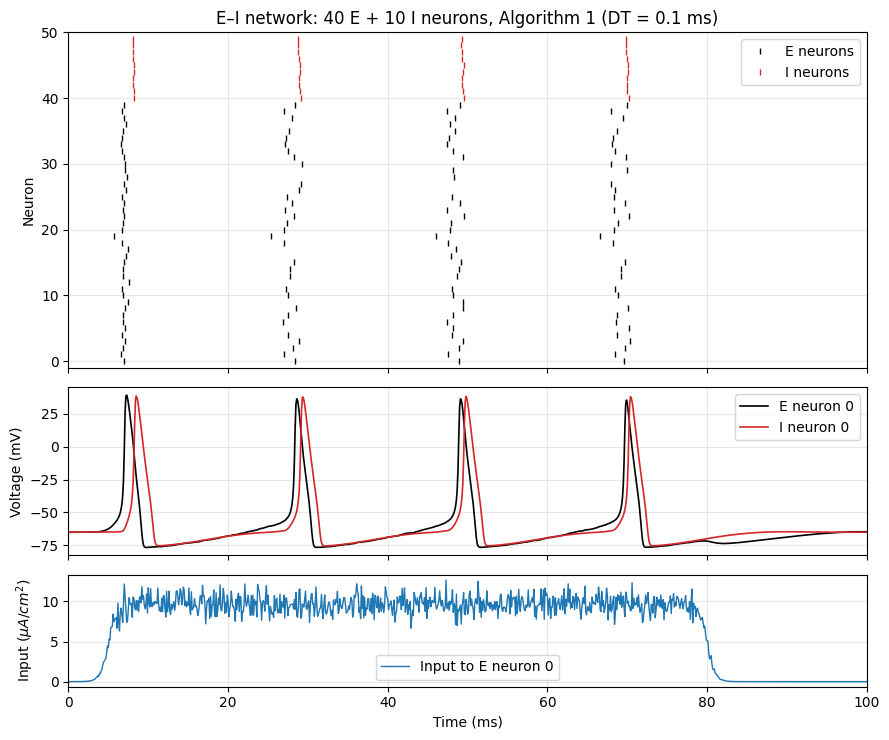

In [68]:
def spike_times(v, threshold=0.0):
    """Spike times of every neuron: upward crossings of the threshold, linearly interpolated between grid points."""
    spikes = []
    for x in v.T:
        i = np.flatnonzero((x[:-1] < threshold) & (x[1:] >= threshold))
        spikes.append(t[i] + (threshold - x[i]) / (x[i + 1] - x[i]) * DT)
    return spikes


def raster(ax, spikes):
    """Raster plot of the spike times: E neurons in black, I neurons in red."""
    times = np.concatenate(spikes)
    neuron = np.repeat(np.arange(N), [len(s) for s in spikes])
    ax.plot(times[neuron < N_E], neuron[neuron < N_E], "|", color="black", ms=4, label="E neurons")
    ax.plot(times[neuron >= N_E], neuron[neuron >= N_E], "|", color="tab:red", ms=4, label="I neurons")
    ax.set_ylim(-1, N)


spikes = spike_times(v)

fig, (ax_raster, ax_v, ax_u) = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True,
                                            gridspec_kw={"height_ratios": [3, 1.5, 1]})
raster(ax_raster, spikes)
ax_raster.set_ylabel("Neuron")
ax_raster.set_title(f"E–I network: {N_E} E + {N_I} I neurons, Algorithm 1 (DT = {DT} ms)")
ax_raster.legend(loc="upper right")

ax_v.plot(t, v[:, 0], color="black", lw=1.2, label="E neuron 0")
ax_v.plot(t, v[:, N_E], color="tab:red", lw=1.2, label="I neuron 0")
ax_v.set_ylabel("Voltage (mV)")
ax_v.legend(loc="upper right")

ax_u.plot(t, u[:, 0], color="tab:blue", lw=1, label="Input to E neuron 0")
ax_u.set_xlabel("Time (ms)")
ax_u.set_ylabel(r"Input ($\mu A/cm^2$)")
ax_u.set_xlim(0, T_FINAL)
ax_u.legend(loc="lower center")
for ax in (ax_raster, ax_v, ax_u):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Reference solution (numerical integration)

To verify Algorithm 1, the full network ODE in $(v, m, h, n, s)$, with $5N$ states, is integrated directly with an adaptive 8th-order Runge–Kutta method (DOP853) at tolerance $10^{-10}$.

* Both solve the *same* problem: the parameters, the rates, the initial state `x0` and the input `u` are the ones defined above, not copies.
* The input is only known on the grid `t`, because of its frozen noise. Between two grid points it is taken to be linear in time, and the integrator is restarted at every grid point, so that it never steps over a kink of the input.
* Within each cell $[t_i, t_{i+1}]$, the step sizes of the integrator are controlled by the tolerance, not by `DT`, so its accuracy does not depend on Algorithm 1's grid.
* The reference is therefore obtained **exactly at the grid points of Algorithm 1**, and the two are compared at identical times.

This cell is independent of the GPU. It takes about a minute for 5000 neurons.

In [69]:
from scipy.integrate import solve_ivp

RTOL = ATOL = 1e-10


def network_rhs(time, y, i):
    """Right-hand side of the network ODE on the cell [t_i, t_{i+1}], where the input is linear in time."""
    v_, m_, h_, n_, s_ = y.reshape(5, N)
    g_syn = np.where(is_exc, G_IE / N_I * s_[inh].sum(), G_EI / N_E * s_[exc].sum())   # I -> E and E -> I
    i_ion = (g_na * m_**3 * h_ * (v_ - E_NA) + g_k * n_**4 * (v_ - E_K) + g_l * (v_ - E_L)
             + g_syn * (v_ - E_syn))
    alpha_m, beta_m, alpha_h, beta_h, alpha_n, beta_n = rates(v_)
    alpha_s = ALPHA_SYN / (1.0 + np.exp(-(v_ - V_SYN) / K_SYN))
    frac = (time - t[i]) / DT
    u_now = (1 - frac) * u[i] + frac * u[i + 1]
    return np.concatenate([u_now - i_ion,
                           alpha_m * (1 - m_) - beta_m * m_,
                           alpha_h * (1 - h_) - beta_h * h_,
                           alpha_n * (1 - n_) - beta_n * n_,
                           alpha_s * (1 - s_) - s_ / tau_syn])


start = time.perf_counter()
y = x0.ravel()                           # same initial state as Algorithm 1
v_ref = np.empty((len(t), N))            # (time, neuron), like v
v_ref[0] = y[:N]
for i in range(len(t) - 1):
    sol = solve_ivp(network_rhs, (t[i], t[i + 1]), y, method="DOP853", args=(i,), rtol=RTOL, atol=ATOL)
    if not sol.success:
        raise RuntimeError(f"Reference solver failed at t = {t[i]:.2f} ms: {sol.message}")
    y = sol.y[:, -1]
    v_ref[i + 1] = y[:N]
print(f"Reference solution computed in {time.perf_counter() - start:.1f} s")

Reference solution computed in 8.0 s


## Comparison: Algorithm 1 vs. reference

The two solutions are compared through their spikes: the number of spikes of every neuron and, for the neurons that fire the same number of spikes in both, the spike times.

The paper reports this comparison for the network of 50 neurons (`N_E, N_I = 40, 10`): every neuron fires the same number of spikes as in the reference, with a median spike-time difference of 17.7 µs.

Algorithm 1: 531 iterations on a fixed grid of 1000 steps (DT = 0.1 ms)
Neurons with the same number of spikes: 50 / 50
Spike-time difference |Algorithm 1 - reference|: median 17.7 µs, max 18575.1 µs


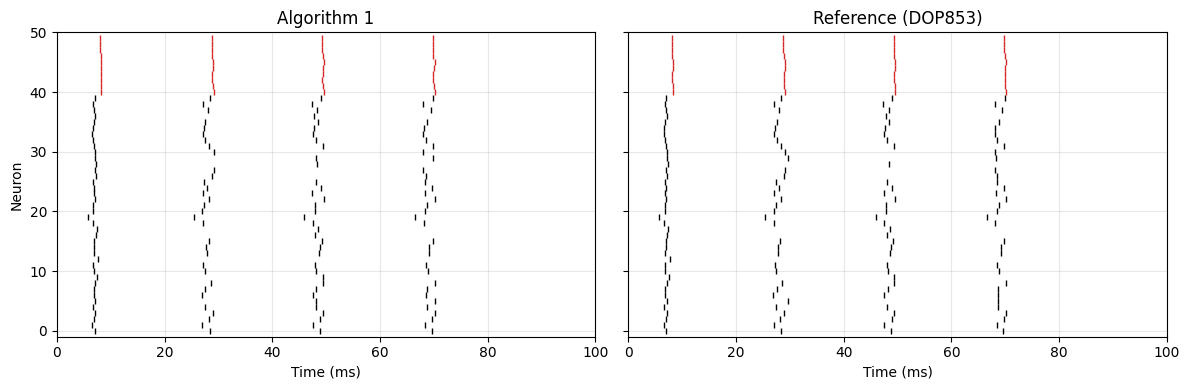

In [70]:
spikes_ref = spike_times(v_ref)
same_count = [len(a) == len(b) for a, b in zip(spikes, spikes_ref)]
shifts = np.abs(np.concatenate([a - b for a, b, same in zip(spikes, spikes_ref, same_count) if same]))

print(f"Algorithm 1: {sum(iterations)} iterations on a fixed grid of {len(t) - 1} steps (DT = {DT} ms)")
print(f"Neurons with the same number of spikes: {sum(same_count)} / {N}")
print(f"Spike-time difference |Algorithm 1 - reference|: median {np.median(shifts) * 1e3:.1f} µs, "
      f"max {np.max(shifts) * 1e3:.1f} µs")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, spikes_plot, title in ((axes[0], spikes, "Algorithm 1"), (axes[1], spikes_ref, "Reference (DOP853)")):
    raster(ax, spikes_plot)
    ax.set_title(title)
    ax.set_xlabel("Time (ms)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Neuron")
axes[0].set_xlim(0, T_FINAL)
plt.tight_layout()
plt.show()